Perform Random Forest & Gradient Boost Regressor using Sktime Library on milk dataset
-

1. conda create -n sktime-env python=3.11
2. conda activate sktime-env
3. conda install -c conda-forge sktime
4. conda install conda-forge::statsmodels
5. conda install conda-forge::pmdarima
6. conda install conda-forge::matplotlib
7. conda install conda-forge::seaborn
8. conda list

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sktime.forecasting.compose import make_reduction
from sktime.forecasting.model_selection import temporal_train_test_split
from sktime.performance_metrics.forecasting import MeanSquaredError
from sktime.utils.plotting import plot_series
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.ensemble import RandomForestRegressor
import os
os.chdir("C:/Users/dbda.STUDENTSDC/Desktop/Practical Machine Learning/Datasets")

In [38]:
df = pd.read_csv("monthly-milk-production-pounds-p.csv", index_col=0)
df

,Milk
Month,
1962-01,589
1962-02,561
1962-03,640
1962-04,656
1962-05,727
...,...
1975-08,858
1975-09,817
1975-10,827


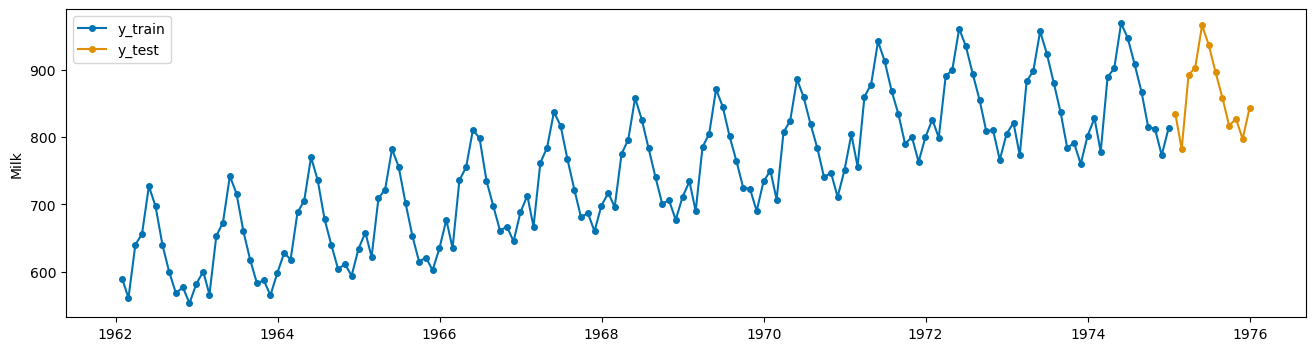

In [39]:
df.index = pd.date_range(start = '1962-01-01',periods = len(df),freq = 'ME') # time indexing must for sktime
y =df['Milk']
y_train,y_test = temporal_train_test_split(y,test_size=12)
plot_series(y_train,y_test,labels=["y_train","y_test"])
plt.legend()
plt.show()

Random Forest Regressor
-

In [40]:
fh = np.arange(1,len(y_test)+1)
regressor = RandomForestRegressor(random_state=25)
forecaster = make_reduction(regressor,window_length=10) # our data start from 11th obs 
forecaster.fit(y_train)
y_pred = forecaster.predict(fh)
rmse = MeanSquaredError(square_root=True)
print(rmse(y_test,y_pred))

71.45569373161713


c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)


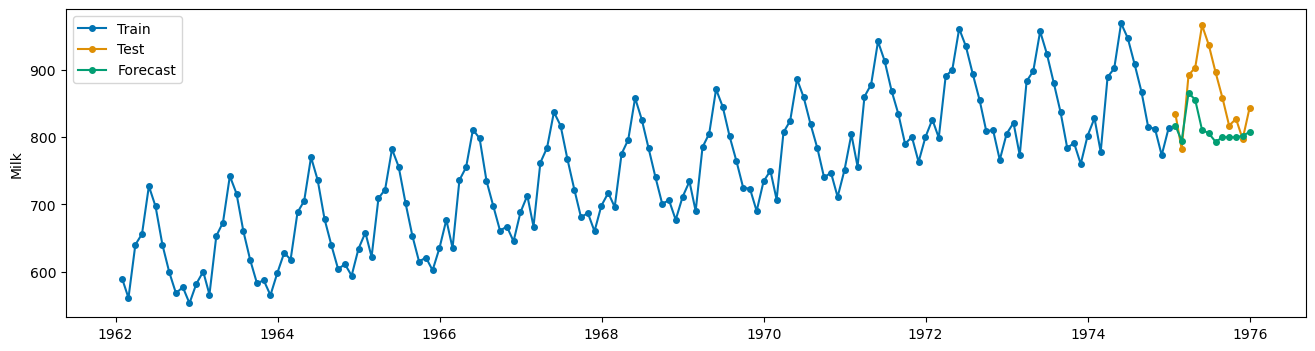

In [41]:
plot_series(y_train,y_test,y_pred,labels=["Train","Test","Forecast"])
plt.legend()
plt.show()

Hyperparameter Tuning for a Time Series model using the sktime library
-

Basic Grid Search
-

In [42]:
from sktime.forecasting.model_selection import ForecastingGridSearchCV, SlidingWindowSplitter

We fit the forecaster on an initial window which is 80% of the historical data then use temporal sliding window cross-validation to find optimal hyper-parameters

In [43]:
regressor = RandomForestRegressor(random_state=25)
forecaster = make_reduction(regressor,strategy="recursive")
param_grid = {'window_length': [7,8,10,12,15]}
cv = SlidingWindowSplitter(initial_window=int(len(y_train)*0.8),window_length=20)
gscv = ForecastingGridSearchCV(forecaster, strategy="refit", cv=cv, scoring=rmse,param_grid=param_grid)
gscv.fit(y_train)

ForecastingGridSearchCV(cv=SlidingWindowSplitter(initial_window=124,
                                                 window_length=20),
                        forecaster=RecursiveTabularRegressionForecaster(estimator=RandomForestRegressor(random_state=25)),
                        param_grid={'window_length': [7, 8, 10, 12, 15]},
                        scoring=MeanSquaredError(square_root=True))

In [44]:
print(gscv.best_params_)
print(gscv.best_score_)
print(rmse(y_test,y_pred))

{'window_length': 8}
21.1828125
71.45569373161713


Composite Grid Search
-

In [45]:
forecaster = make_reduction(regressor,window_length=15,strategy="recursive")
param_grid = {'window_length': [7,8,10,12,15],
              'estimator__max_features':['sqrt','log2']}
cv = SlidingWindowSplitter(initial_window=int(len(y_train)*0.8),window_length=24)
gscv = ForecastingGridSearchCV(forecaster, strategy="refit", cv=cv, scoring=rmse,param_grid=param_grid)
gscv.fit(y_train)

ForecastingGridSearchCV(cv=SlidingWindowSplitter(initial_window=124,
                                                 window_length=24),
                        forecaster=RecursiveTabularRegressionForecaster(estimator=RandomForestRegressor(random_state=25),
                                                                        window_length=15),
                        param_grid={'estimator__max_features': ['sqrt', 'log2'],
                                    'window_length': [7, 8, 10, 12, 15]},
                        scoring=MeanSquaredError(square_root=True))

In [46]:
print(gscv.best_params_)
print(gscv.best_score_)

{'estimator__max_features': 'sqrt', 'window_length': 12}
19.406250000000004


c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)


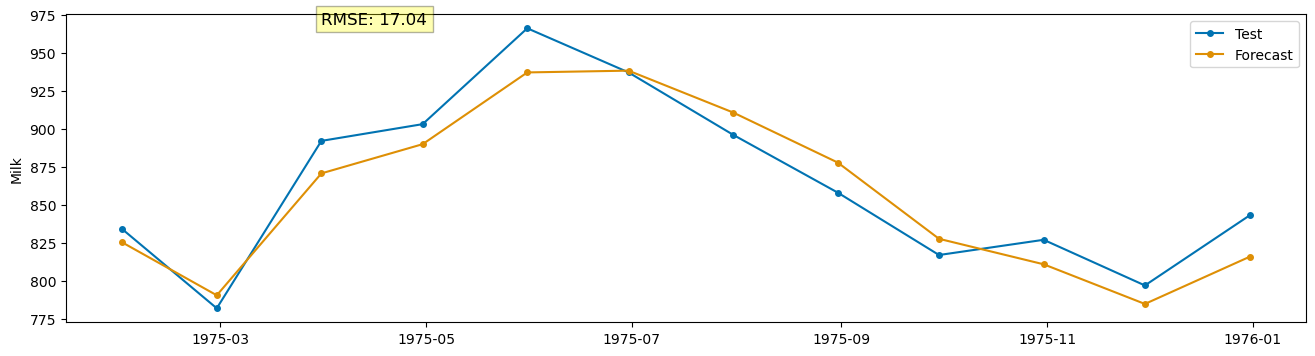

In [47]:
best_forecaster = gscv.best_forecaster_
y_pred = best_forecaster.predict(fh)
plot_series(y_test,y_pred,labels=["Test","Forecast"])
plt.text(y.index[-10],max(y),f'RMSE: {rmse(y_test,y_pred):.2f}',fontsize =12,bbox=dict(facecolor='yellow', alpha=0.3))
plt.legend()
plt.show()

Gradient Boosting Regressor
-

In [48]:
from sklearn.ensemble import GradientBoostingRegressor

regressor = GradientBoostingRegressor(random_state=25)
forecaster = make_reduction(regressor,window_length=15,strategy="recursive")
param_grid = {'window_length': [7,8,10,12,15],
              'estimator__learning_rate':np.linspace(0.01,0.2,5),
              'estimator__n_estimators':[50,100,150],
              'estimator__max_depth':[3,4,5,6]}
cv = SlidingWindowSplitter(initial_window=int(len(y_train)*0.8),window_length=24)
gscv = ForecastingGridSearchCV(forecaster, strategy="refit", cv=cv, scoring=rmse,param_grid=param_grid)
gscv.fit(y_train)
print(gscv.best_params_)
print(gscv.best_score_)

{'estimator__learning_rate': np.float64(0.15250000000000002), 'estimator__max_depth': 3, 'estimator__n_estimators': 150, 'window_length': 12}
16.574283153251127


c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:863: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  return r * to_offset(fh.freq)
c:\Users\dbda.STUDENTSDC\.conda\envs\sktime-env\Lib\site-packages\sktime\forecasting\base\_fh.py:877: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  absolute = pd.DatetimeIndex(absolute, freq=fh.freq)


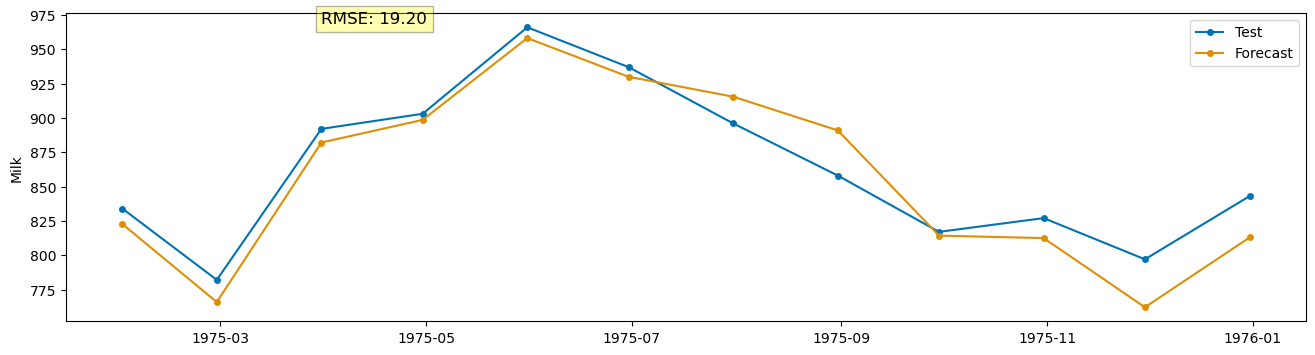

In [49]:
best_forecaster = gscv.best_forecaster_
y_pred = best_forecaster.predict(fh)
plot_series(y_test,y_pred,labels=["Test","Forecast"])
plt.text(y.index[-10],max(y),f'RMSE: {rmse(y_test,y_pred):.2f}',fontsize =12,bbox=dict(facecolor='yellow', alpha=0.3))
plt.legend()
plt.show()